In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
data = pd.read_csv('data.csv')
data.head()

,V1,V2,labels
0,2.072345,-3.241693,0
1,17.936710,15.784810,0
2,1.083576,7.319176,0
3,11.120670,14.406780,0
4,23.711550,2.557729,0


In [2]:
x = data.drop(['labels'],axis = 1)
y = data.loc[:,'labels']

In [3]:
from sklearn.cluster import MeanShift,estimate_bandwidth
bandwidth = estimate_bandwidth(x,n_samples=500)
ms = MeanShift(bandwidth=bandwidth)
ms.fit(x)

MeanShift(bandwidth=30.84663454820215)

In [4]:
from sklearn.metrics import accuracy_score
y_predict = ms.predict(x)
acs = accuracy_score(y,y_predict)
acs

0.31966666666666665

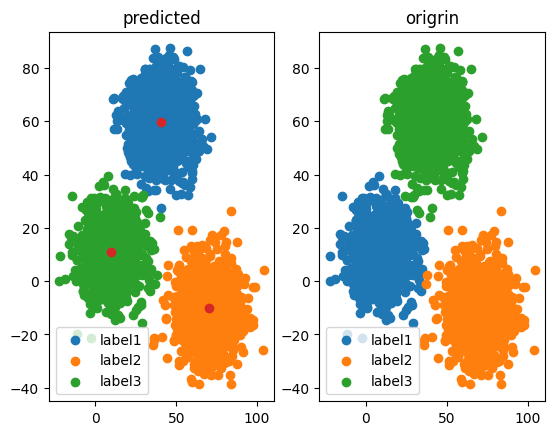

In [5]:
centers2 = ms.cluster_centers_
#模型正确率低，图示预测后的图和中⼼点，与原图做⽐较
fig2 = plt.subplot(121)
plt.title('predicted')
label1 = plt.scatter(data.loc[:,'V1'][y_predict==0],data.loc[:,'V2'][y_predict==0])
label2 = plt.scatter(data.loc[:,'V1'][y_predict==1],data.loc[:,'V2'][y_predict==1])
label3 = plt.scatter(data.loc[:,'V1'][y_predict==2],data.loc[:,'V2'][y_predict==2])
plt.legend((label1,label2,label3),('label1','label2','label3'))
plt.scatter(centers2[:,0],centers2[:,1])
fig3 = plt.subplot(122)
plt.title('origrin')
label1 = plt.scatter(data.loc[:,'V1'][y==0],data.loc[:,'V2'][y==0])
label2 = plt.scatter(data.loc[:,'V1'][y==1],data.loc[:,'V2'][y==1])
label3 = plt.scatter(data.loc[:,'V1'][y==2],data.loc[:,'V2'][y==2])
plt.legend((label1,label2,label3),('label1','label2','label3'))
plt.show()

In [6]:
y_corrected = []
for i in y_predict:
    if i == 0:
        y_corrected.append(2)
    elif i == 1:
        y_corrected.append(1)
    else:
        y_corrected.append(0)

In [7]:
acs = accuracy_score(y,y_corrected)
y_corrected = np.array(y_corrected)
acs

0.997

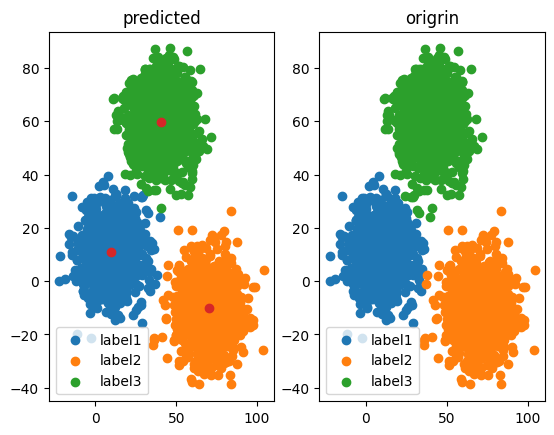

In [8]:
fig4 = plt.subplot(121)
plt.title('predicted')
label1 = plt.scatter(data.loc[:,'V1'][y_corrected==0],data.loc[:,'V2'][y_corrected==0])
label2 = plt.scatter(data.loc[:,'V1'][y_corrected==1],data.loc[:,'V2'][y_corrected==1])
label3 = plt.scatter(data.loc[:,'V1'][y_corrected==2],data.loc[:,'V2'][y_corrected==2])
plt.legend((label1,label2,label3),('label1','label2','label3'))
plt.scatter(centers2[:,0],centers2[:,1])
fig5 = plt.subplot(122)
plt.title('origrin')
label1 = plt.scatter(data.loc[:,'V1'][y==0],data.loc[:,'V2'][y==0])
label2 = plt.scatter(data.loc[:,'V1'][y==1],data.loc[:,'V2'][y==1])
label3 = plt.scatter(data.loc[:,'V1'][y==2],data.loc[:,'V2'][y==2])
plt.legend((label1,label2,label3),('label1','label2','label3'))
plt.show()